# 05 · Customer value and risk

Notebook 04 found 7–8 personas per hotel. This notebook asks the revenue-management questions:

1. Which personas are worth their room, once cancellations are counted?
2. Who takes the rooms on the nights that matter (peak nights), and how many of those rooms are
   "ghosts" that are booked and then cancelled?
3. When does each persona book, and what does that imply for holding rooms back?
4. How much risk do group bookings carry?
5. Which partners (agencies) bring value, and which bring risk?
6. Can risk be summarised in a few readable rules, and do they hold over time?

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

sys.path.insert(0, str(Path.cwd().parent))
from src.simulator import load_train, ROOMS
from src.plotting import PERSONA_COLORS
from src.customers import (PERSONA_ORDER, add_block_size, booking_frame, explode_nights,
                           fit_personas, kpi)
from src import plotting as P

P.setup()
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)
HOTELS = list(ROOMS)
K = {"Downtown Hotel": 7, "Seaside Hotel": 8}               # chosen in notebook 04
full = add_block_size(load_train())
data = {}
for h in HOTELS:
    data[h] = booking_frame(full, h)
    data[h]["persona"], _ = fit_personas(data[h], K[h])
PERSONAS = {h: [p for p in PERSONA_ORDER if p in set(data[h].persona)] for h in HOTELS}

## 1 · Value against risk

x: cancellation rate. y: average nightly rate *if the guest shows up*. The dotted curves join
points with the same **expected value per room-night**, `(1 − p_cancel) × rate`. Bubble size =
share of the room-nights requested.

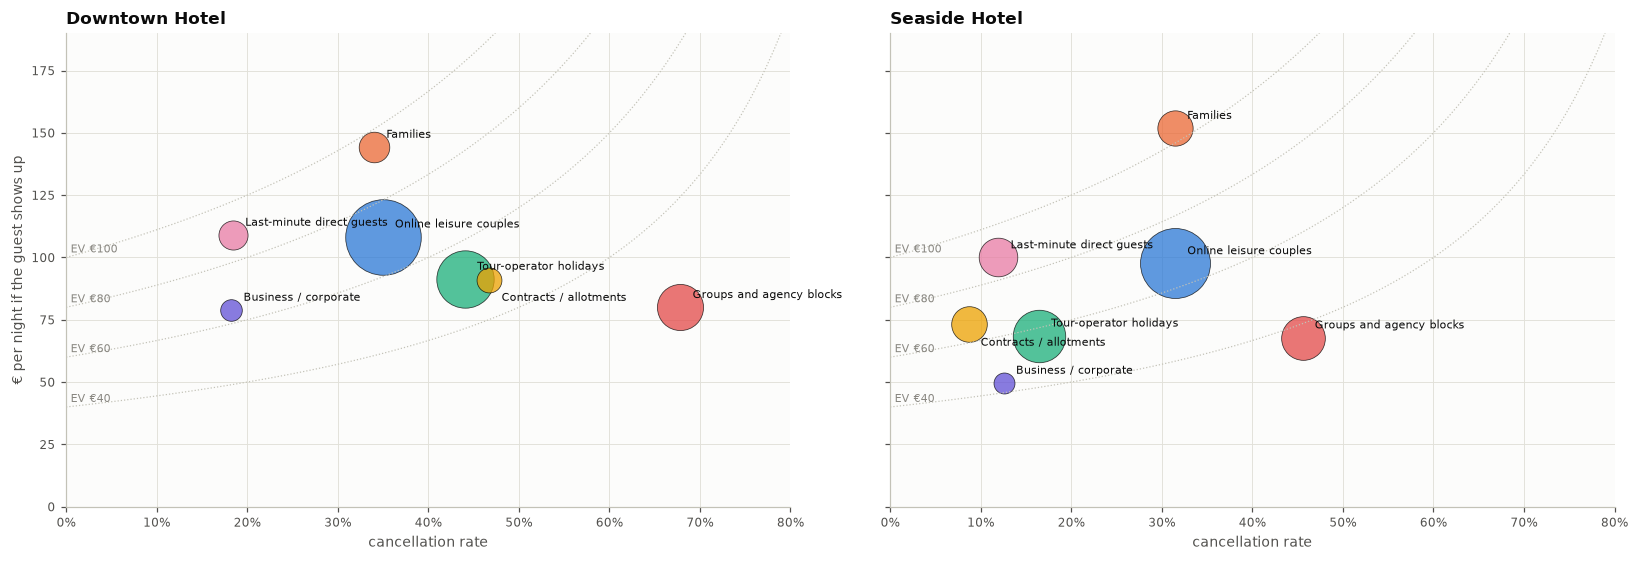

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)
for ax, h in zip(axes, HOTELS):
    d = data[h]
    t = d.groupby("persona").apply(kpi, ref=d, include_groups=False).reindex(PERSONAS[h])
    rate = d.groupby("persona").nightly_rate.mean().reindex(PERSONAS[h])
    for p in PERSONAS[h]:
        ax.scatter(t.loc[p, "cancel_rate"], rate[p], s=t.loc[p, "share_requested_room_nights"] * 6000,
                   color=PERSONA_COLORS[p], alpha=.75, edgecolor="black", lw=.5)
        ax.annotate(p, (t.loc[p, "cancel_rate"], rate[p]), fontsize=7.5, textcoords="offset points",
                    xytext=(8, -14) if p == "Contracts / allotments" else (8, 6))
    xs = np.linspace(0, .9, 100)
    for ev in (40, 60, 80, 100):
        ax.plot(xs, ev / (1 - xs), color=P.LIGHT, lw=.8, ls=":")
        ax.text(.005, ev + 2, f"EV €{ev}", fontsize=7, color=P.MUTED)
    ax.set(title=h, xlabel="cancellation rate", xlim=(0, .8), ylim=(0, 190))
    ax.xaxis.set_major_formatter(P.PCT)
axes[0].set_ylabel("€ per night if the guest shows up")
P.save(fig, "value_vs_risk")
plt.tight_layout(); plt.show()

**Rate alone is misleading.** Online couples pay well (~€105 at Downtown) but cancel a third of
the time; groups and agency blocks combine a low rate with the highest risk: about €26 (Downtown)
and €36 (Seaside)
of expected value per room-night. **Families** sit at the top of both hotels (high rate, average
risk), and **direct guests** score through reliability rather than price. At Seaside, tour
operators and contracts are cheap but safe, so their expected value is close to the online
couples'. This is exactly the quantity the policy compares: probability of showing up × rate,
against what the room would earn from someone else.

## 2 · Peak nights and ghost rooms

A **peak night** is a night on which the guests who showed up exceed capacity: every room given to
one booking was taken from another. A **ghost room-night** is a room-night that was booked and then
cancelled. On peak nights ghosts are pure loss unless the hotel overbooked to cover them.

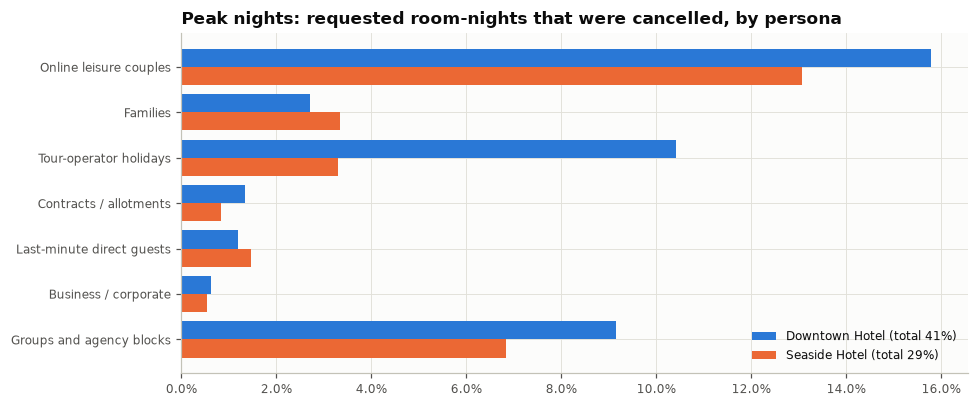

peak nights  share of peak room-nights  ghost room-nights (share of all peak room-nights)
hotel          persona                                                                                                             
Downtown Hotel Online leisure couples           0.731                      0.423                                              0.158
               Families                         0.731                      0.070                                              0.027
               Tour-operator holidays           0.731                      0.242                                              0.104
               Contracts / allotments           0.731                      0.035                                              0.013
               Last-minute direct guests        0.731                      0.057                                              0.012
               Business / corporate             0.731                      0.032                                              0.006
               Groups and agency blocks         0.731                      0.141                                              0.092
Seaside Hotel  Online leisure couples           0.793                      0.345                                              0.131
               Families                         0.793                      0.092                                              0.033
               Tour-operator holidays           0.793                      0.191                                              0.033
               Contracts / allotments           0.793                      0.093                                              0.008
               Last-minute direct guests        0.793                      0.103                                              0.015
               Business / corporate             0.793                      0.028                                              0.005
               Groups and agency blocks         0.793                      0.148                                              0.068

In [3]:
rows = []
for h in HOTELS:
    N = explode_nights(data[h], ["persona"])
    N = N[(N.night >= "2015-07-15") & (N.night <= "2016-12-31")]
    shown = N.groupby("night").show.sum()
    N["peak"] = N.night.map(shown > ROOMS[h])
    pk = N[N.peak]
    for p in PERSONAS[h]:
        rows.append({"hotel": h, "persona": p, "peak nights": (shown > ROOMS[h]).mean(),
                     "share of peak room-nights": (pk.persona == p).mean(),
                     "ghost room-nights (share of all peak room-nights)": ((pk.persona == p) & (pk.show == 0)).mean()})
ghost = pd.DataFrame(rows)
g = ghost.pivot(index="persona", columns="hotel", values="ghost room-nights (share of all peak room-nights)").reindex(PERSONA_ORDER)
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(g))
for i, h in enumerate(HOTELS):
    ax.barh(y + (i - .5) * .4, g[h], .4, color=P.HOTEL_COLORS[h], label=f"{h} (total {g[h].sum():.0%})")
ax.set_yticks(y, g.index); ax.invert_yaxis(); ax.xaxis.set_major_formatter(P.PCT)
ax.set(title="Peak nights: requested room-nights that were cancelled, by persona")
ax.legend()
plt.tight_layout(); plt.show()
ghost.set_index(["hotel", "persona"]).round(3)

On peak nights (73% of nights at Downtown, 79% at Seaside) about **41% of the requested
room-nights at Downtown and 29% at Seaside are ghosts**. Online couples alone account for 13–16
points, simply because they are the largest group; tour operators (Downtown) and groups are
responsible for most of the rest. These are the rooms that overbooking must recover, and the
reason a per-booking probability is worth more than a hotel-wide cancellation rate.

## 3 · When each persona books

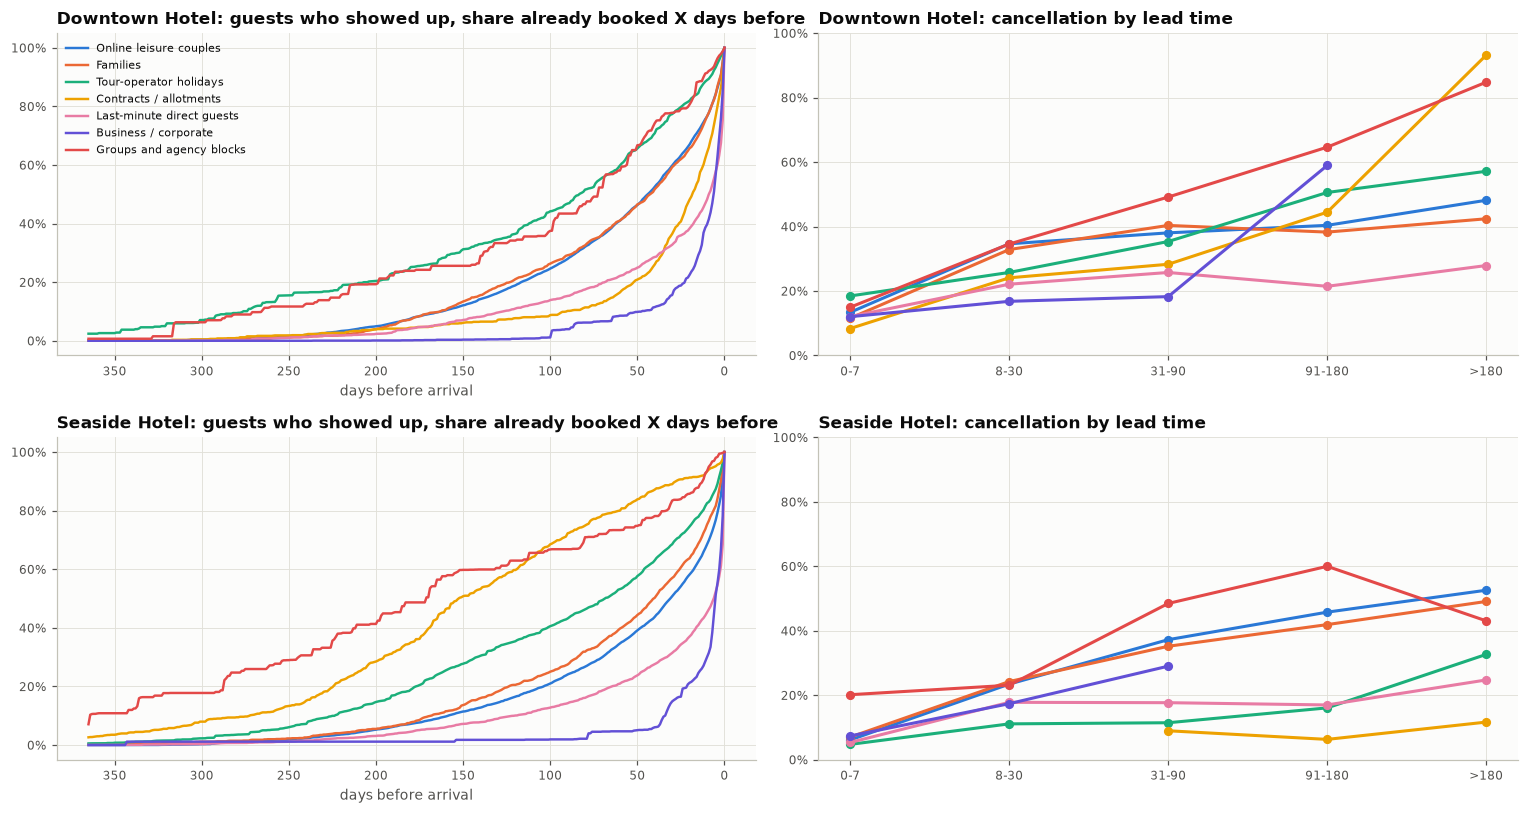

,Downtown Hotel,Seaside Hotel
booked in the last 30 days,,
Online leisure couples,0.36,0.40
Families,0.36,0.36
Tour-operator holidays,0.17,0.29
Contracts / allotments,0.41,0.11
Last-minute direct guests,0.65,0.66
Business / corporate,0.80,0.83
Groups and agency blocks,0.10,0.12


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))
grid = np.arange(0, 366)
lbl = ["0-7", "8-30", "31-90", "91-180", ">180"]
for r, h in enumerate(HOTELS):
    d = data[h]
    for p in PERSONAS[h]:
        lead = np.sort(d[(d.persona == p) & (d.cancelled == 0)].days_ahead.values)
        axes[r, 0].plot(grid, 1 - np.searchsorted(lead, grid) / len(lead), color=PERSONA_COLORS[p], label=p, lw=1.6)
    axes[r, 0].invert_xaxis(); axes[r, 0].yaxis.set_major_formatter(P.PCT)
    axes[r, 0].set(title=f"{h}: guests who showed up, share already booked X days before", xlabel="days before arrival")
    gb = d.groupby([pd.cut(d.days_ahead, [-1, 7, 30, 90, 180, 1000], labels=lbl), "persona"], observed=True).cancelled
    t = gb.mean().where(gb.size() >= 80).unstack().reindex(columns=PERSONAS[h])
    for p in PERSONAS[h]:
        axes[r, 1].plot(lbl, t[p], marker="o", color=PERSONA_COLORS[p], label=p)
    axes[r, 1].yaxis.set_major_formatter(P.PCT); axes[r, 1].set(title=f"{h}: cancellation by lead time", ylim=(0, 1))
axes[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()
pd.concat({h: (data[h].days_ahead <= 30).groupby(data[h].persona).mean().reindex(PERSONA_ORDER) for h in HOTELS},
          axis=1).rename_axis("booked in the last 30 days").round(2)

**Those who book late show up; those who book early cancel.** Business travellers and direct
guests make 65–83% of their bookings in the last month; groups only 10–12%. For every persona
cancellations rise with lead time. A request for August that arrives in March competes for its
room with demand that has not arrived yet, and that later demand is more reliable. The policy
must price the room against the demand still to come, which is what the bid price does.

## 4 · How much risk does a group carry?

Groups end unanimously in 93–98% of cases (notebook 03). A small simulation shows what that does to
the risk of a night: 60 rooms sold, each guest shows up with probability 0.7 (42 expected), in
three portfolios with the **same expected number of guests**.

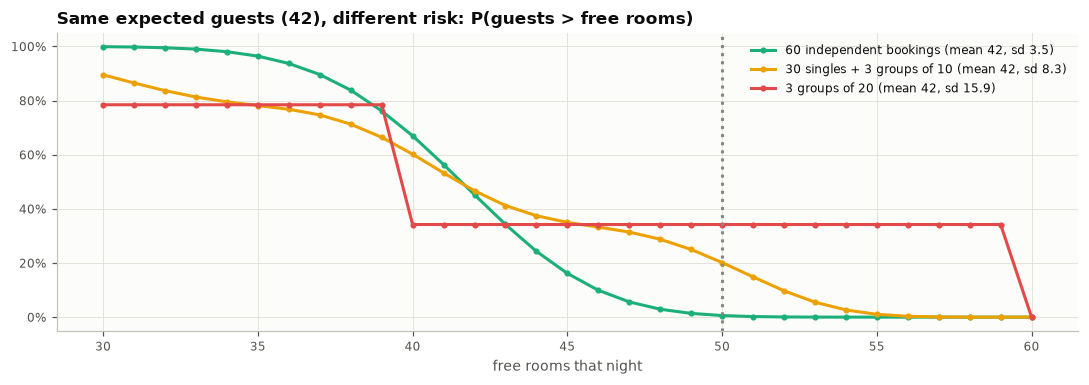

{'60 independent bookings': '0.6%',
 '30 singles + 3 groups of 10': '20.2%',
 '3 groups of 20': '34.2%'}

In [5]:
rng = np.random.default_rng(1)
sims = 200_000
scen = {"60 independent bookings": rng.binomial(60, .7, sims),
        "30 singles + 3 groups of 10": rng.binomial(30, .7, sims) + rng.binomial(1, .7, (sims, 3)).sum(1) * 10,
        "3 groups of 20": rng.binomial(1, .7, (sims, 3)).sum(1) * 20}
free = np.arange(30, 61)
fig, ax = plt.subplots(figsize=(10, 3.6))
for (lab, s_), c in zip(scen.items(), [P.OURS, P.YELLOW, P.RED]):
    ax.plot(free, [(s_ > f).mean() for f in free], color=c, lw=2, marker="o", ms=3,
            label=f"{lab} (mean {s_.mean():.0f}, sd {s_.std():.1f})")
ax.axvline(50, color=P.MUTED, ls=":")
ax.set(title="Same expected guests (42), different risk: P(guests > free rooms)", xlabel="free rooms that night")
ax.yaxis.set_major_formatter(P.PCT); ax.legend()
plt.tight_layout(); plt.show()
{k: f"{(v > 50).mean():.1%}" for k, v in scen.items()}

With the same 42 expected guests, the probability of exceeding 50 free rooms goes from **0.6%**
with independent bookings to **20%** with three groups of 10 and **34%** with three groups of 20.
Counting expected guests is not enough when they arrive in blocks: the cancellation model has to
know that a request belongs to a block (it does, through the live counters of identical requests),
and the blocks' cancellation probability, often near 0 or 1, does the rest.

## 5 · Partners: which agencies bring value?

`agent` identifies the selling agency. A scorecard per agency (volume, risk, value) and a
clustering of the agencies with at least 100 bookings into **partner types**.

In [6]:
both = pd.concat([data[h].assign(hotel=h) for h in HOTELS])
both["hotel_yield"] = both.hotel.map({h: data[h].realized.sum() / data[h].nights.sum() for h in HOTELS})
sc = both[both.agent_id != "none"].groupby(["hotel", "agent_id"]).agg(
    bookings=("booking_id", "size"), cancel_rate=("cancelled", "mean"), median_lead=("days_ahead", "median"),
    mean_block=("block", "mean"), nights=("nights", "sum"), revenue=("realized", "sum"),
    hotel_yield=("hotel_yield", "first"), main_persona=("persona", lambda s: s.mode()[0]))
sc["yield_index"] = sc.revenue / sc.nights / sc.hotel_yield        # 1 = hotel average per requested room-night
sc["revenue_share"] = sc.revenue / sc.index.get_level_values(0).map({h: data[h].realized.sum() for h in HOTELS})
for h in HOTELS:
    v = sc.loc[h].sort_values("bookings", ascending=False)
    print(f"{h}: {len(v)} agencies · top 1 brings {v.bookings.iloc[0] / data[h].shape[0]:.0%} of bookings and "
          f"{v.revenue_share.iloc[0]:.0%} of revenue · top 5: {v.bookings.head(5).sum() / data[h].shape[0]:.0%} of bookings")
sc.sort_values("bookings", ascending=False).head(12).round(2)

Downtown Hotel: 183 agencies · top 1 brings 36% of bookings and 46% of revenue · top 5: 61% of bookings
Seaside Hotel: 161 agencies · top 1 brings 33% of bookings and 31% of revenue · top 5: 47% of bookings


bookings  cancel_rate  median_lead  mean_block  nights     revenue  hotel_yield               main_persona  yield_index  revenue_share
hotel          agent_id                                                                                                                                        
Downtown Hotel 9            18626         0.39         52.0        1.35   59792  3993229.92        58.17     Online leisure couples         1.15           0.46
Seaside Hotel  240           8859         0.36         50.0        1.24   36436  2299045.74        65.57     Online leisure couples         0.96           0.31
Downtown Hotel 1             6808         0.72        276.0       19.87   16815   371733.54        58.17   Groups and agency blocks         0.38           0.04
               7             2111         0.14         44.0        1.19    7315   563877.20        58.17     Online leisure couples         1.33           0.06
               6             2068         0.38        247.0       31.49    4396   271709.25        58.17     Tour-operator holidays         1.06           0.03
               14            1966         0.20         35.0        1.26    6646   588439.84        58.17  Last-minute direct guests         1.52           0.07
Seaside Hotel  250           1677         0.16         38.0        1.09    7222   764093.51        65.57  Last-minute direct guests         1.61           0.10
Downtown Hotel 28            1108         0.05         43.0        1.21    3753   281456.14        58.17     Tour-operator holidays         1.29           0.03
               3             1100         0.54        159.0       11.94    3236   115078.71        58.17     Tour-operator holidays         0.61           0.01
Seaside Hotel  241            985         0.12         47.0        1.13    4657   355568.06        65.57     Online leisure couples         1.16           0.05
Downtown Hotel 37             912         0.65         98.0       52.73    2559    81555.43        58.17   Groups and agency blocks         0.55           0.01
               8              798         0.31         64.0        1.28    2866   203884.89        58.17     Online leisure couples         1.22           0.02

In [7]:
big = sc[sc.bookings >= 100].copy()
Z = StandardScaler().fit_transform(np.column_stack([np.log(big.bookings), big.cancel_rate, np.log1p(big.median_lead),
                                                    np.log(big.mean_block), big.yield_index]))
big["cluster"] = KMeans(4, n_init=20, random_state=0).fit_predict(Z)
TOTAL_REVENUE = sum(data[h].realized.sum() for h in HOTELS)
prof = big.groupby("cluster").agg(agencies=("bookings", "size"), bookings=("bookings", "sum"), cancel_rate=("cancel_rate", "median"),
                                  median_lead=("median_lead", "median"), mean_block=("mean_block", "median"),
                                  yield_index=("yield_index", "median"), revenue=("revenue", "sum"))
prof["share_of_total_revenue"] = prof.pop("revenue") / TOTAL_REVENUE
prof.round(2)

,agencies,bookings,cancel_rate,median_lead,mean_block,yield_index,share_of_total_revenue
cluster,,,,,,,
0,29,7067,0.12,69.0,1.20,1.07,0.15
1,24,14759,0.64,168.0,21.64,0.46,0.07
2,8,36130,0.18,45.5,1.22,1.26,0.56
3,11,4584,0.40,161.0,12.43,1.02,0.05


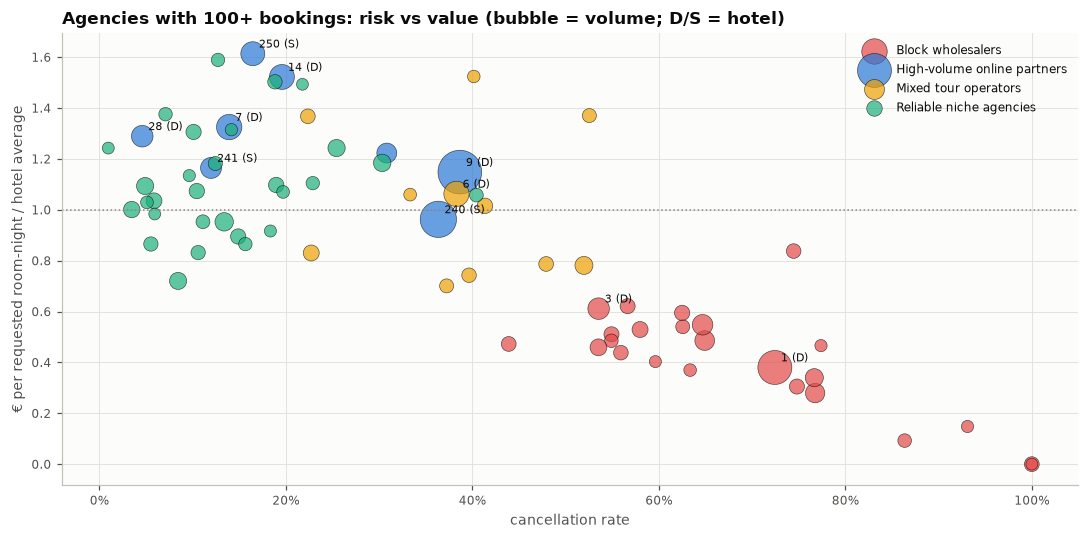

,agencies,bookings,cancel_rate,yield_index,share_of_total_revenue
partner_type,,,,,
Block wholesalers,24,14759,0.64,0.46,0.07
High-volume online partners,8,36130,0.18,1.26,0.56
Mixed tour operators,11,4584,0.40,1.02,0.05
Reliable niche agencies,29,7067,0.12,1.07,0.15


In [8]:
PARTNER_NAMES = {0: "Reliable niche agencies", 1: "Block wholesalers", 2: "High-volume online partners",
                 3: "Mixed tour operators"}
big["partner_type"] = big.cluster.map(PARTNER_NAMES)
PCOL = dict(zip(PARTNER_NAMES.values(), [P.AQUA, P.RED, P.BLUE, P.YELLOW]))
fig, ax = plt.subplots(figsize=(10, 5))
for t, g in big.groupby("partner_type"):
    ax.scatter(g.cancel_rate, g.yield_index, s=np.sqrt(g.bookings) * 6, color=PCOL[t], alpha=.7, edgecolor="black", lw=.4, label=t)
for (h, a), r in big.sort_values("bookings", ascending=False).head(10).iterrows():
    ax.annotate(f"{a} ({h.split()[0][0]})", (r.cancel_rate, r.yield_index), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.axhline(1, color=P.MUTED, ls=":", lw=1)
ax.set(title="Agencies with 100+ bookings: risk vs value (bubble = volume; D/S = hotel)",
       xlabel="cancellation rate", ylabel="€ per requested room-night / hotel average")
ax.xaxis.set_major_formatter(P.PCT); ax.legend(fontsize=8)
P.save(fig, "partner_types")
plt.tight_layout(); plt.show()
big.groupby("partner_type").agg(agencies=("bookings", "size"), bookings=("bookings", "sum"),
                                cancel_rate=("cancel_rate", "median"), yield_index=("yield_index", "median"),
                                share_of_total_revenue=("revenue", lambda r: r.sum() / TOTAL_REVENUE)).round(2)

**A few partners carry each hotel.** One OTA brings about a third of the bookings at both hotels
(Downtown agent 9: 36% of bookings, 46% of revenue). Clustering the 72 agencies with at least 100
bookings on volume, risk, lead time, block size and value gives four partner types:

| Partner type | Profile | What to do |
|---|---|---|
| **High-volume online partners** (8 agencies) | the big OTAs and direct-booking partners: most of the revenue, value above the hotel average | the core: overbook them booking by booking |
| **Reliable niche agencies** (29) | small volumes, ~12% cancellations, value at or above average | protect; a good historical rate is a reason to accept |
| **Mixed tour operators** (11) | blocks of ~12 rooms booked five months ahead, ~40% cancellations | judge by agency, not by channel |
| **Block wholesalers** (24) | blocks of ~20 rooms, ~5 months ahead, 64% cancellations, less than half the average value | the least valuable use of a room on peak nights |

The agency's smoothed historical cancellation rate is one of the model's features
(`agent_te`) and one of the most frequent reasons in the decision explanations (notebook 09).

## 6 · Risk in ten readable rules

Personas describe customers; to *decide*, risk must be summarised directly. A tree with 10 leaves
(at least 500 bookings each) per hotel, trained on bookings made **before July 2016** and tested on
those made after. It uses only request-time fields.

In [9]:
def rules_frame(d):
    X = pd.get_dummies(d[["sales_segment", "guest_type"]], dtype=int)
    X.columns = X.columns.str.replace("sales_segment_", "segment ").str.replace("guest_type_", "type ")
    return X.assign(**{"lead days": d.days_ahead, "identical rows": d.block, "nights": d.nights, "kids": d.kids,
                       "adults": d.adults, "has agent": (d.agent_id != "none").astype(int)})


def leaf_rules(tree, cols, X):
    tr, out = tree.tree_, {}
    def walk(node, conds):
        if tr.children_left[node] == -1:
            out[node] = " & ".join(conds) or "all"
            return
        f, thr = cols[tr.feature[node]], tr.threshold[node]
        if set(np.unique(X[f])) <= {0, 1}:
            left, right = f"not {f}", f
        else:
            left, right = f"{f} ≤ {np.floor(thr):.0f}", f"{f} ≥ {np.ceil(thr):.0f}"
        walk(tr.children_left[node], conds + [left]); walk(tr.children_right[node], conds + [right])
    walk(0, [])
    return out


evals, tables = [], {}
for h in HOTELS:
    d = data[h]
    X = rules_frame(d)
    train = (d.booking_date < "2016-07-01").to_numpy()
    tree = DecisionTreeClassifier(max_leaf_nodes=10, min_samples_leaf=500, random_state=0).fit(X[train], d.cancelled[train])
    leaf = pd.Series(tree.apply(X), index=d.index)
    t = pd.DataFrame({"rule": pd.Series(leaf_rules(tree, list(X.columns), X)),
                      "bookings (train)": d[train].groupby(leaf[train]).size(),
                      "cancel (train)": d[train].groupby(leaf[train]).cancelled.mean(),
                      "cancel (after Jul 2016)": d[~train].groupby(leaf[~train]).cancelled.mean(),
                      "median rate": d.groupby(leaf).nightly_rate.median()}).sort_values("cancel (train)")
    t.index = [f"R{i + 1}" for i in range(len(t))]
    tables[h] = t
    y = d.cancelled[~train]
    lookup = lambda col: col[~train].map(d[train].groupby(col[train]).cancelled.mean()).fillna(d.cancelled[train].mean()).clip(.001, .999)
    for name, p in {"hotel average": np.full((~train).sum(), d.cancelled[train].mean()),
                    "personas": lookup(d.persona), "10-rule tree": tree.predict_proba(X[~train])[:, 1].clip(.001, .999)}.items():
        evals.append({"hotel": h, "method": name, "AUC": roc_auc_score(y, p) if np.std(p) > 0 else .5,
                      "log-loss": log_loss(y, p), "mean predicted": np.mean(p), "actual": y.mean()})
pd.DataFrame(evals).set_index(["hotel", "method"]).round(3)

AUC  log-loss  mean predicted  actual
hotel          method                                                
Downtown Hotel hotel average  0.500     0.653           0.440   0.302
               personas       0.562     0.606           0.357   0.302
               10-rule tree   0.669     0.561           0.302   0.302
Seaside Hotel  hotel average  0.500     0.514           0.281   0.196
               personas       0.598     0.502           0.273   0.196
               10-rule tree   0.695     0.459           0.206   0.196

In [10]:
fmt = {"bookings (train)": "{:,.0f}", "cancel (train)": "{:.0%}", "cancel (after Jul 2016)": "{:.0%}", "median rate": "€{:.0f}"}
tables["Downtown Hotel"].style.format(fmt, na_rep="–").set_properties(subset=["rule"], **{"text-align": "left"}) \
    .background_gradient(subset=["cancel (train)", "cancel (after Jul 2016)"], cmap=P.ORANGES, vmin=0, vmax=1)

,rule,bookings (train),cancel (train),cancel (after Jul 2016),median rate
R1,identical rows ≤ 13 & lead days ≤ 14,"7,427",15%,16%,€98
R2,identical rows ≤ 13 & lead days ≥ 15 & type Transient-Party,"6,606",22%,26%,€86
R3,identical rows ≤ 13 & lead days ≥ 15 & not type Transient-Party & identical rows ≤ 4 & not segment Online TA,"3,505",22%,16%,€85
R4,identical rows ≥ 14 & type Transient-Party & lead days ≤ 273 & identical rows ≤ 57,"2,668",32%,68%,€85
R5,identical rows ≥ 14 & type Transient-Party & lead days ≥ 274 & identical rows ≥ 33,571,33%,–,€115
R6,identical rows ≤ 13 & lead days ≥ 15 & not type Transient-Party & identical rows ≤ 4 & segment Online TA,"11,382",41%,40%,€107
R7,identical rows ≥ 14 & type Transient-Party & lead days ≤ 273 & identical rows ≥ 58,544,72%,100%,€102
R8,identical rows ≥ 14 & type Transient-Party & lead days ≥ 274 & identical rows ≤ 32,989,89%,–,€62
R9,identical rows ≤ 13 & lead days ≥ 15 & not type Transient-Party & identical rows ≥ 5,915,91%,58%,€96
R10,identical rows ≥ 14 & not type Transient-Party,"7,401",99%,100%,€75


In [11]:
tables["Seaside Hotel"].style.format(fmt, na_rep="–").set_properties(subset=["rule"], **{"text-align": "left"}) \
    .background_gradient(subset=["cancel (train)", "cancel (after Jul 2016)"], cmap=P.ORANGES, vmin=0, vmax=1)

,rule,bookings (train),cancel (train),cancel (after Jul 2016),median rate
R1,identical rows ≤ 6 & not segment Online TA & lead days ≤ 6,"2,583",5%,7%,€50
R2,identical rows ≤ 6 & not segment Online TA & lead days ≥ 7 & type Contract,"1,120",8%,0%,€70
R3,identical rows ≤ 6 & segment Online TA & lead days ≤ 17,"2,179",8%,11%,€72
R4,identical rows ≤ 6 & not segment Online TA & lead days ≥ 7 & not type Contract,"6,884",16%,16%,€70
R5,identical rows ≤ 6 & segment Online TA & lead days ≥ 18 & identical rows ≤ 1 & lead days ≤ 71,"2,143",33%,35%,€97
R6,identical rows ≥ 7 & type Transient-Party & lead days ≥ 134,854,33%,–,€67
R7,identical rows ≤ 6 & segment Online TA & lead days ≥ 18 & identical rows ≤ 1 & lead days ≥ 72,"3,245",45%,39%,€100
R8,identical rows ≥ 7 & type Transient-Party & lead days ≤ 133,660,47%,15%,€68
R9,identical rows ≤ 6 & segment Online TA & lead days ≥ 18 & identical rows ≥ 2,778,61%,46%,€77
R10,identical rows ≥ 7 & not type Transient-Party,"1,337",99%,–,€68


**Ten rules capture most of the explainable risk.** At Downtown, *bookings that are part of a
block of 14+ identical rows and are not transient-party* cancel 99% of the time (R10: the old
non-refundable agency blocks, recognised without the forbidden `deposit` column), while *small
bookings made at most two weeks ahead* cancel 15–16% (R1). At Seaside the safest rule is
*non-OTA, small, booked within a week* (5–7%), the riskiest again the large non-transient blocks
(99%). (Here "identical rows" counts the whole group as it appears in the file; live, the model
counts the identical requests seen so far.)

Rules on small bookings hold well in the second half of 2016; **rules on blocks move a lot** (at
Downtown R4 goes from 32% to 68%, R9 from 91% to 58%): group behaviour is the least stable part of
the problem.

Out of time, the 10-rule tree ranks bookings clearly better than the personas (AUC 0.67–0.70 vs
0.56–0.60) and is better calibrated. The full model of notebook 07 does better still (AUC
~0.73–0.74 on the same kind of split): personas and rules are for **explaining**; the calibrated
model is for **deciding**.

## 7 · Are personas stable over time?

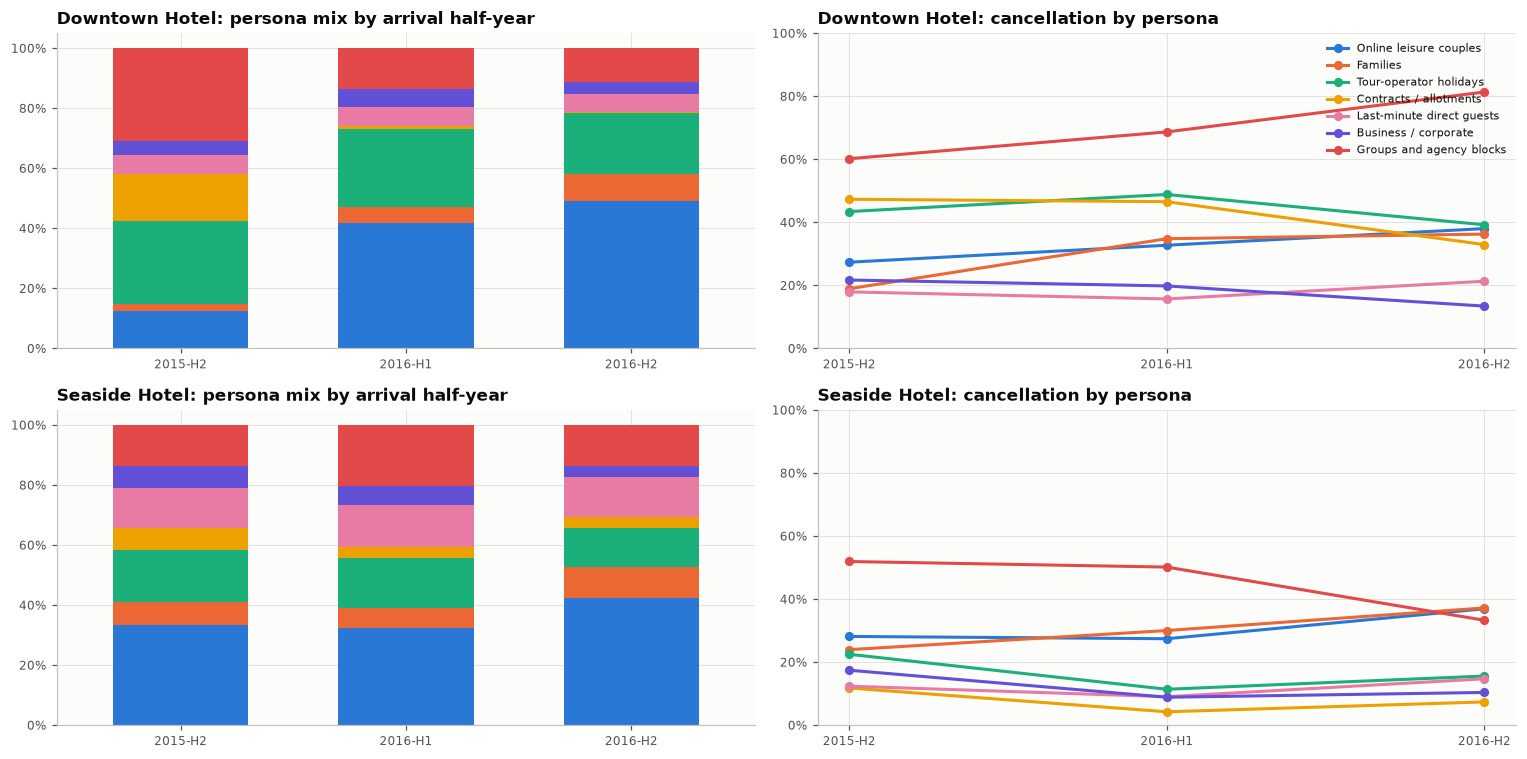

mix                  cancel                
period                                   2015-H2 2016-H1 2016-H2 2015-H2 2016-H1 2016-H2
               persona                                                                  
Downtown Hotel Online leisure couples       0.12    0.42    0.49    0.27    0.33    0.38
               Families                     0.02    0.05    0.09    0.19    0.35    0.36
               Tour-operator holidays       0.28    0.26    0.20    0.43    0.49    0.39
               Contracts / allotments       0.16    0.01    0.00    0.47    0.47    0.33
               Last-minute direct guests    0.06    0.06    0.06    0.18    0.16    0.21
               Business / corporate         0.04    0.06    0.04    0.22    0.20    0.13
               Groups and agency blocks     0.31    0.14    0.11    0.60    0.69    0.81
Seaside Hotel  Online leisure couples       0.33    0.33    0.42    0.28    0.27    0.37
               Families                     0.08    0.06    0.11    0.24    0.30    0.37
               Tour-operator holidays       0.18    0.17    0.13    0.22    0.11    0.16
               Contracts / allotments       0.07    0.04    0.03    0.12    0.04    0.07
               Last-minute direct guests    0.13    0.14    0.13    0.12    0.09    0.15
               Business / corporate         0.07    0.06    0.04    0.17    0.09    0.10
               Groups and agency blocks     0.14    0.20    0.14    0.52    0.50    0.33

In [12]:
per = ["2015-H2", "2016-H1", "2016-H2"]
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
out = {}
for r, h in enumerate(HOTELS):
    d = data[h]
    mix = d.groupby(["period", "persona"]).size().unstack().reindex(index=per, columns=PERSONAS[h])
    mix = mix.div(mix.sum(axis=1), axis=0)
    mix.plot.bar(stacked=True, ax=axes[r, 0], color=[PERSONA_COLORS[p] for p in PERSONAS[h]], rot=0, legend=False, width=.6)
    axes[r, 0].yaxis.set_major_formatter(P.PCT); axes[r, 0].set(title=f"{h}: persona mix by arrival half-year", xlabel="")
    c = d.groupby(["period", "persona"]).cancelled.mean().unstack().reindex(index=per, columns=PERSONAS[h])
    for p in PERSONAS[h]:
        axes[r, 1].plot(per, c[p], marker="o", color=PERSONA_COLORS[p], label=p)
    axes[r, 1].yaxis.set_major_formatter(P.PCT); axes[r, 1].set(title=f"{h}: cancellation by persona", ylim=(0, 1))
    out[h] = pd.concat({"mix": mix.T, "cancel": c.T}, axis=1)
axes[0, 1].legend(fontsize=7)
plt.tight_layout(); plt.show()
pd.concat(out).round(2)

**The customer mix is moving.** At Downtown, online couples go from 12% of bookings in the second
half of 2015 to 49% a year later, while groups fall from 31% to 11% and contracts disappear. Their
cancellation rates move as well: online couples and families cancel more and more (27% → 38%,
19% → 36%), the remaining groups cancel even more (60% → 81%). Seaside is more stable, but online
couples and families also drift upwards.

For a model frozen for a year this means: weight recent months more (half-life 6 months), avoid
columns whose meaning drifts, and validate on later periods only (notebook 07).

## Recommendations, and where they live in the system

| # | Recommendation | Evidence | Implemented as |
|---|---|---|---|
| 1 | Rank requests by expected value **per room-night** | families/direct €83–99 vs groups €27–36 per requested room-night | the policy compares the nightly rate with the night's bid price (notebook 08) |
| 2 | Keep rooms for late, reliable demand | 65–83% of business/direct guests book in the last month and cancel 12–18% | bid price = rate of the marginal guest still expected |
| 3 | Overbook the online channel booking by booking | 13–16 points of ghost rooms on peak nights | calibrated per-booking `p_cancel` |
| 4 | Treat a block as one bet | 96% unanimous outcomes; overflow risk 0.6% → 34% | live counters of identical requests as model features |
| 5 | Judge partners by their record | agencies range from 5% to 72% cancellations | agent id + smoothed historical rate |
| 6 | Expect drift | persona mix and rates move within a year | recency weights, drifting columns excluded, temporal validation |